## project car price prediction

## 1.import library

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import joblib

## 2. Dataset load and check

In [3]:
df= pd.read_csv("C:\\Users\\ek949\\Downloads\\car_price_prediction_dataset_2500_improved.csv")
df

,Car ID,Brand,Year,Engine Size,Fuel Type,Transmission,Condition,Model,Price
0,1,Honda,2021,0.0,Electric,Manual,Used,City,31694.0
1,2,Toyota,2020,2.5,Diesel,Manual,Used,Camry,44213.0
2,3,Toyota,2019,3.0,Diesel,Manual,Like New,Corolla,48350.0
3,4,Kia,2009,1.8,Diesel,Automatic,Used,Carens,23028.0
4,5,Mercedes,2019,0.0,Electric,Automatic,New,GLA,45702.0
...,...,...,...,...,...,...,...,...,...
2495,2496,BMW,2009,1.8,Diesel,Manual,Like New,3 Series,35531.0
2496,2497,Maruti,2017,1.5,Petrol,Manual,New,Baleno,36309.0
2497,2498,Honda,2011,1.2,Diesel,Automatic,New,City,28274.0
2498,2499,Ford,2021,2.5,Diesel,Automatic,Like New,EcoSport,48632.0


In [4]:
df.head()

,Car ID,Brand,Year,Engine Size,Fuel Type,Transmission,Condition,Model,Price
0,1,Honda,2021,0.0,Electric,Manual,Used,City,31694.0
1,2,Toyota,2020,2.5,Diesel,Manual,Used,Camry,44213.0
2,3,Toyota,2019,3.0,Diesel,Manual,Like New,Corolla,48350.0
3,4,Kia,2009,1.8,Diesel,Automatic,Used,Carens,23028.0
4,5,Mercedes,2019,0.0,Electric,Automatic,New,GLA,45702.0


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2500 entries, 0 to 2499
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Car ID        2500 non-null   int64  
 1   Brand         2500 non-null   object 
 2   Year          2500 non-null   int64  
 3   Engine Size   2500 non-null   float64
 4   Fuel Type     2500 non-null   object 
 5   Transmission  2500 non-null   object 
 6   Condition     2500 non-null   object 
 7   Model         2500 non-null   object 
 8   Price         2500 non-null   float64
dtypes: float64(2), int64(2), object(5)
memory usage: 175.9+ KB


In [6]:
df.isnull().sum()

Car ID          0
Brand           0
Year            0
Engine Size     0
Fuel Type       0
Transmission    0
Condition       0
Model           0
Price           0
dtype: int64

In [7]:
df.describe()

,Car ID,Year,Engine Size,Price
count,2500.00000,2500.000000,2500.000000,2500.000000
mean,1250.50000,2016.433600,1.580280,37675.798400
std,721.83216,5.161652,0.885271,10587.802615
min,1.00000,2008.000000,0.000000,11299.000000
25%,625.75000,2012.000000,1.000000,29976.250000
50%,1250.50000,2016.000000,1.500000,37330.000000
75%,1875.25000,2021.000000,2.000000,45192.000000
max,2500.00000,2025.000000,3.000000,71561.000000


In [8]:
print("Rows and columns:",df.shape)


Rows and columns: (2500, 9)


## 3. EDA(professional grapoh)

In [9]:
## price distribution

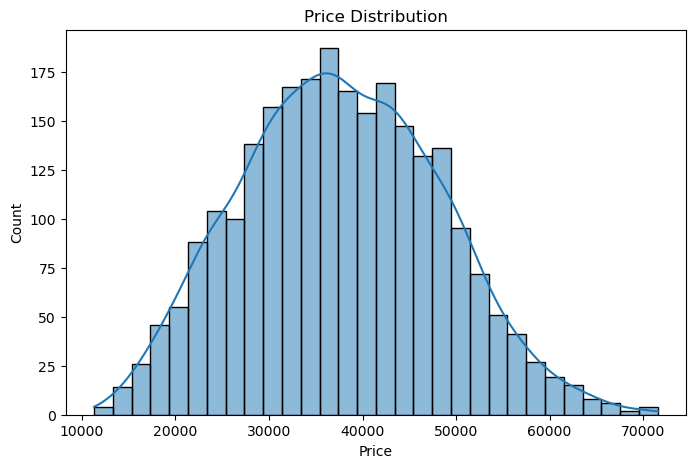

In [10]:
plt.figure(figsize=(8,5))
sns.histplot(df["Price"], bins=30, kde=True)
plt.title("Price Distribution")
plt.show()

In [11]:
## Engine vs Price

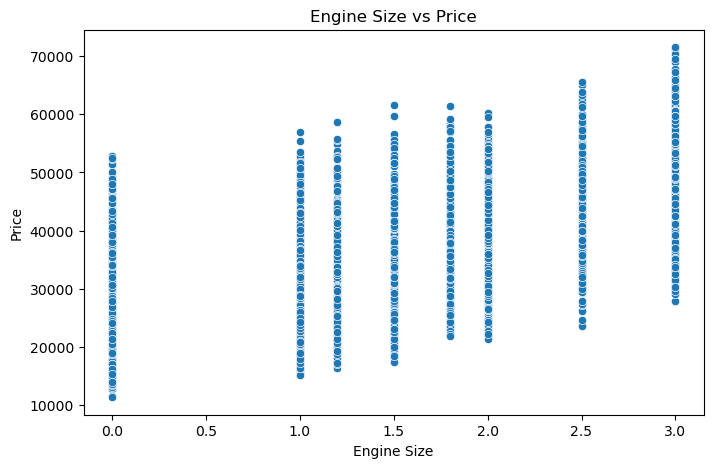

In [12]:
plt.figure(figsize=(8,5))
sns.scatterplot(x="Engine Size", y="Price", data=df)
plt.title("Engine Size vs Price")
plt.show()

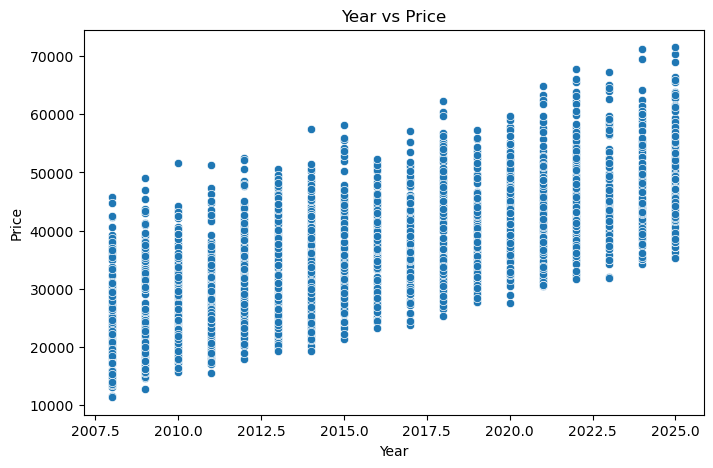

In [13]:
plt.figure(figsize=(8,5))
sns.scatterplot(x="Year", y="Price", data=df)
plt.title("Year vs Price")
plt.show()

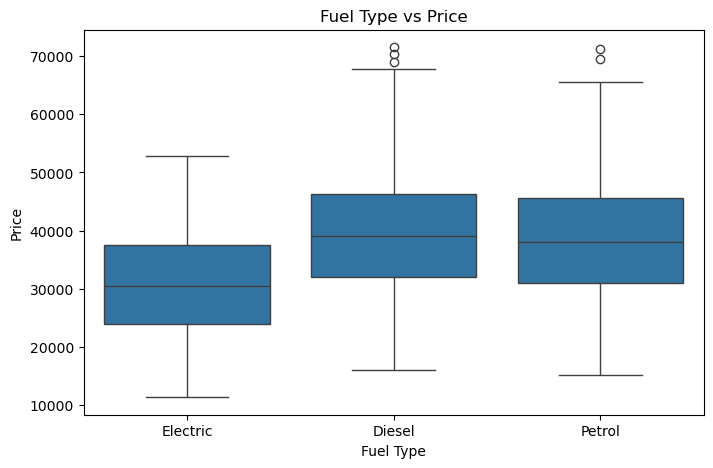

In [14]:
plt.figure(figsize=(8,5))
sns.boxplot(x="Fuel Type", y="Price", data=df)
plt.title("Fuel Type vs Price")
plt.show()

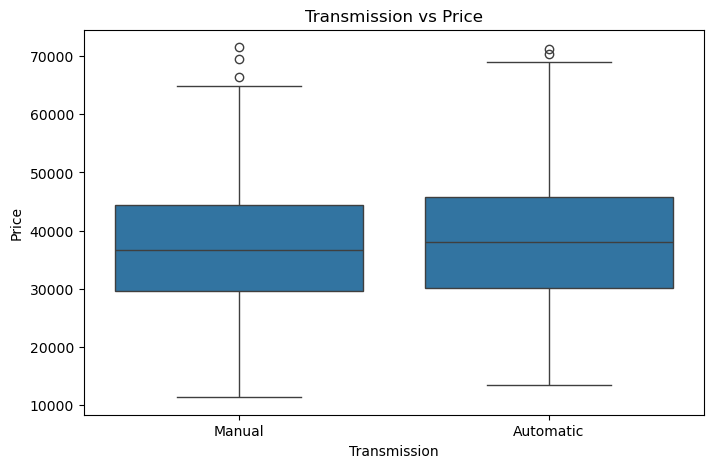

In [15]:
plt.figure(figsize=(8,5))
sns.boxplot(x="Transmission", y="Price", data=df)
plt.title("Transmission vs Price")
plt.show()

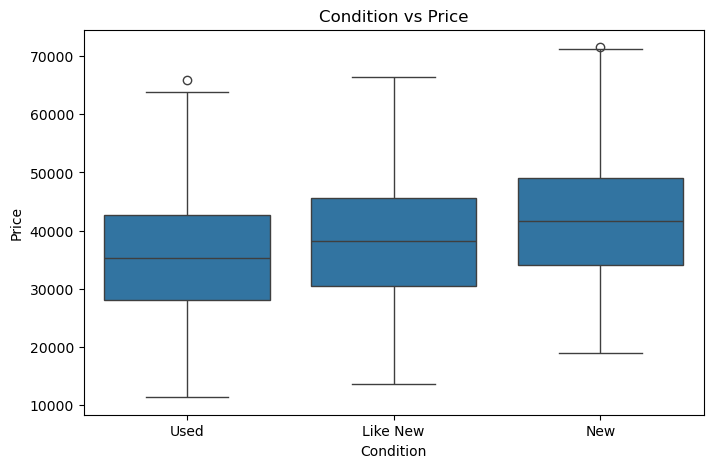

In [16]:
plt.figure(figsize=(8,5))
sns.boxplot(x="Condition", y="Price", data=df)
plt.title("Condition vs Price")
plt.show()

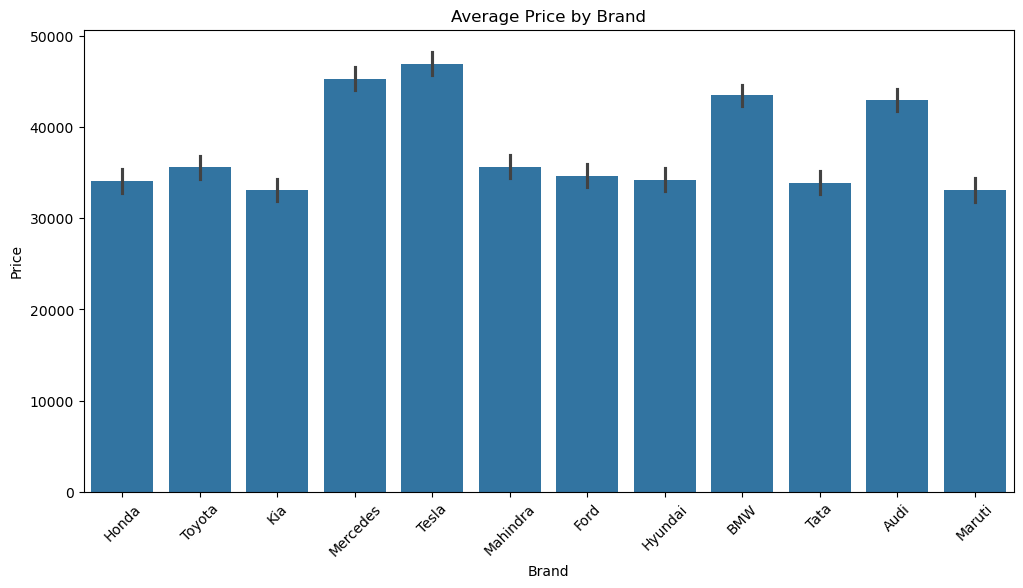

In [17]:
plt.figure(figsize=(12,6))
sns.barplot(x="Brand", y="Price", data=df)
plt.xticks(rotation=45)
plt.title("Average Price by Brand")
plt.show()

## 4.Data preprocessing

## Label Encoder $ one-Hot Encoding

In [18]:
X = df.drop("Price", axis=1)
y = df["Price"]

In [19]:
X = X.drop("Car ID", axis=1)

In [20]:
categorical_features = ["Brand", "Fuel Type", "Transmission", "Condition", "Model"]

numerical_features = ["Year", "Engine Size"]

In [21]:
preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ],
    remainder="passthrough"
)

## train test split

In [22]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

## 5.Linear regression model $ (Train)

In [23]:
model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

In [24]:
## Model Train

In [25]:
model.fit(X_train, y_train)

C:\Users\ek949\AppData\Local\anaconda3\Lib\site-packages\sklearn\compose\_column_transformer.py:1623: FutureWarning: 
The format of the columns of the 'remainder' transformer in ColumnTransformer.transformers_ will change in version 1.7 to match the format of the other transformers.
At the moment the remainder columns are stored as indices (of type int). With the same ColumnTransformer configuration, in the future they will be stored as column names (of type str).
To use the new behavior now and suppress this warning, use ColumnTransformer(force_int_remainder_cols=False).

  warnings.warn(


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Brand', 'Fuel Type',
                                                   'Transmission', 'Condition',
                                                   'Model'])])),
                ('regressor', LinearRegression())])

In [26]:
## prediction $ Accuracy

In [27]:
y_pred = model.predict(X_test)

In [28]:
from sklearn.metrics import r2_score

r2 = r2_score(y_test, y_pred)

print("R² Score:", r2)
print("Accuracy:", round(r2 * 100, 2), "%")

R² Score: 0.995742293398444
Accuracy: 99.57 %


In [29]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

print("MAE :", mean_absolute_error(y_test, y_pred))
print("MSE :", mean_squared_error(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))

MAE : 606.385694056048
MSE : 491334.69253575074
RMSE: 700.952703494145


## .Model save

In [30]:
import joblib

joblib.dump(model, "car_price_prediction_model.pkl")

print("Model Saved Successfully")

Model Saved Successfully


## saved model load

In [31]:
loaded_model = joblib.load("car_price_prediction_model.pkl")

## 8 new car price predict (Final)

In [32]:
new_car = pd.DataFrame({
    "Brand": ["Toyota"],
    "Year": [2023],
    "Engine Size": [2.0],
    "Fuel Type": ["Petrol"],
    "Transmission": ["Automatic"],
    "Condition": ["New"],
    "Model": ["Camry"]
})

prediction = loaded_model.predict(new_car)

print("Predicted Price:", prediction[0])

Predicted Price: 50299.18167367391


In [33]:
import pandas as pd
import joblib

# Load Saved Model
model = joblib.load("car_price_prediction_model.pkl")

# User Input
brand = input("Enter Brand: ")
year = int(input("Enter Year: "))
engine = float(input("Enter Engine Size: "))
fuel = input("Enter Fuel Type (Petrol/Diesel/Electric): ")
transmission = input("Enter Transmission (Manual/Automatic): ")
condition = input("Enter Condition (New/Like New/Used): ")
car_model = input("Enter Model: ")

# Create DataFrame
new_car = pd.DataFrame({
    "Brand": [brand],
    "Year": [year],
    "Engine Size": [engine],
    "Fuel Type": [fuel],
    "Transmission": [transmission],
    "Condition": [condition],
    "Model": [car_model]
})

# Prediction
prediction = model.predict(new_car)

print("\nPredicted Car Price: $", round(prediction[0], 2))

Enter Brand:  Honda
Enter Year:  2021
Enter Engine Size:  0.0
Enter Fuel Type (Petrol/Diesel/Electric):  Electric
Enter Transmission (Manual/Automatic):  Manual
Enter Condition (New/Like New/Used):  Used
Enter Model:  City



Predicted Car Price: $ 30705.86
